# Proyecto AFORE, 04: simulador de ahorro para el retiro

Con lo de los notebooks anteriores calculo cuánto podría juntar una persona según la AFORE que elija.

Trabajo todo en términos reales (pesos de hoy) con los rendimientos reales del notebook 03, así no tengo que adivinar la inflación futura. Los rendimientos de CONSAR ya vienen netos de comisión, entonces no la resto otra vez. El ahorro mensual lo escribe la persona (lo obligatorio más lo voluntario). Calcularlo desde el sueldo requiere las reglas de aportación vigentes, que cambiaron con la reforma de pensiones, y no las incluí.

Es un ejercicio de escenarios y no una predicción. Suponer que el rendimiento de los últimos 5 años se mantiene por décadas es un supuesto fuerte, y más abajo lo pongo a prueba.

## 1. Preparar los datos

In [1]:
import sys, os
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from limpieza import cargar_y_limpiar, cargar_inpc, agregar_real, PLAZOS
from simulacion import (proyectar, saldo_final, total_aportado, rendimientos_por_afore,
                        ajustar_persistencia, comparar_afores)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170)
os.makedirs("../images/04", exist_ok=True)

def guardar(nombre):
    plt.savefig(f"../images/04/{nombre}.png", dpi=150, bbox_inches="tight")

fmt_pesos = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f} M")

df, gen, sistema = cargar_y_limpiar("../data/10_rendimientos_precio_bolsa.csv")
inpc = cargar_inpc("../data/inpc_mensual.csv")
gen_r = agregar_real(gen, inpc)
sis_r = agregar_real(sistema, inpc)
print("listo")

listo


## 2. Revisar que el cálculo esté bien
Antes de usarlo lo comparo con la fórmula cerrada de una anualidad. Si no coinciden, algo está mal.

In [2]:
S0, A, ANIOS, R = 100_000, 1_500, 30, 3.0
r_m = (1 + R / 100) ** (1 / 12) - 1
n = ANIOS * 12
cerrada = S0 * (1 + r_m) ** n + A * ((1 + r_m) ** n - 1) / r_m
print(f"simulador:        ${saldo_final(S0, A, ANIOS, R):,.2f}")
print(f"fórmula cerrada:  ${cerrada:,.2f}")
print(f"sin rendimiento:  ${saldo_final(S0, A, ANIOS, 0.0):,.2f}  (= {S0:,} + {A:,} x {n} meses)")

simulador:        $1,110,795.80
fórmula cerrada:  $1,110,795.80
sin rendimiento:  $640,000.00  (= 100,000 + 1,500 x 360 meses)


## 3. Un perfil de ejemplo
No es un caso real, solo sirve para ilustrar. Nacido en 1992 (generación SB 90-94), 33 años hoy y retiro a los 65, o sea 32 años de ahorro. Saldo actual de $150,000 y ahorro mensual de $1,800 en pesos de hoy.

In [3]:
FONDO = "90-94"
SALDO_INICIAL = 150_000
APORTE_MENSUAL = 1_800
ANIOS = 32
CRECIMIENTO_APORTE_REAL = 0.0   # % anual por encima de la inflación (0 es que el aporte solo sigue a la inflación)

aportado = total_aportado(SALDO_INICIAL, APORTE_MENSUAL, ANIOS, CRECIMIENTO_APORTE_REAL)
print(f"lo que se pondría en total (sin rendimientos): ${aportado:,.0f}")

lo que se pondría en total (sin rendimientos): $841,200


## 4. Escenario base
Tomo el rendimiento real a 5 años de cada AFORE en esta generación (último mes) y lo supongo constante.

rendimiento real a 5 años (anualizado), % por AFORE:
afore
inbursa          2.71
profuturo        2.46
xxi banorte      2.22
invercap         2.03
sura             2.03
pensionissste    1.57
banamex          1.26
principal        1.21
azteca           0.75
coppel           0.44

promedio ponderado del sistema en la SB 90-94: 1.55%


,rend_real_%,saldo_final,vs_peor_$,vs_peor_%
afore,,,,
inbursa,2.7,1445328.2,530160.1,57.9
profuturo,2.5,1370813.3,455645.2,49.8
xxi banorte,2.2,1304983.9,389815.8,42.6
invercap,2.0,1254674.1,339506.0,37.1
sura,2.0,1254454.7,339286.6,37.1
pensionissste,1.6,1142719.3,227551.2,24.9
banamex,1.3,1074603.3,159435.2,17.4
principal,1.2,1063607.9,148439.7,16.2
azteca,0.7,970562.7,55394.6,6.1


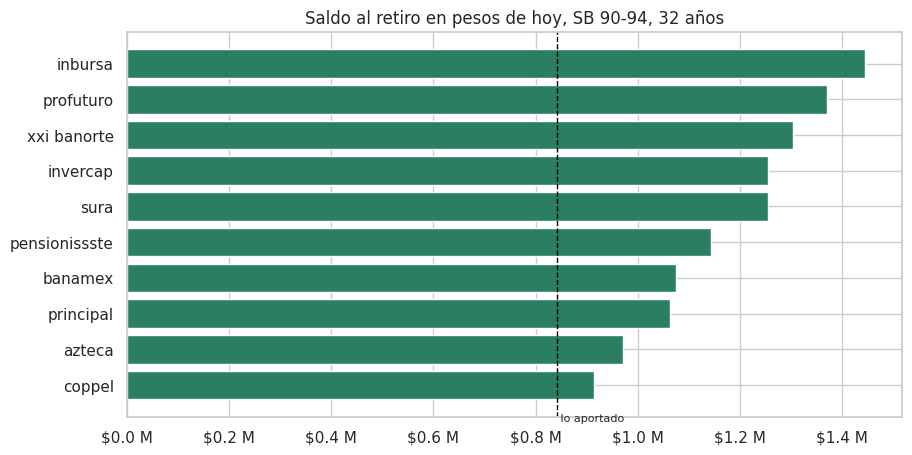

In [4]:
rend = rendimientos_por_afore(gen_r, FONDO, plazo="5 años")
print("rendimiento real a 5 años (anualizado), % por AFORE:")
print(rend.round(2).to_string())

prom_sistema = sis_r[(sis_r["fondo"] == FONDO) & (sis_r["plazo"] == "5 años")].dropna(subset=["real"]).sort_values("fecha")["real"].iloc[-1]
print(f"\npromedio ponderado del sistema en la SB {FONDO}: {prom_sistema:.2f}%")

tabla = comparar_afores(rend, SALDO_INICIAL, APORTE_MENSUAL, ANIOS, CRECIMIENTO_APORTE_REAL)
display(tabla.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
t = tabla.sort_values("saldo_final")
ax.barh(t.index, t["saldo_final"], color="#2a7f62")
ax.axvline(aportado, color="black", ls="--", lw=1)
ax.text(aportado, -0.8, " lo aportado", fontsize=8, va="top")
ax.xaxis.set_major_formatter(fmt_pesos)
ax.set_title(f"Saldo al retiro en pesos de hoy, SB {FONDO}, {ANIOS} años")
ax.set_xlabel("")
guardar("01_saldo_por_afore")
plt.show()

## 5. Mejor AFORE, peor AFORE y promedio

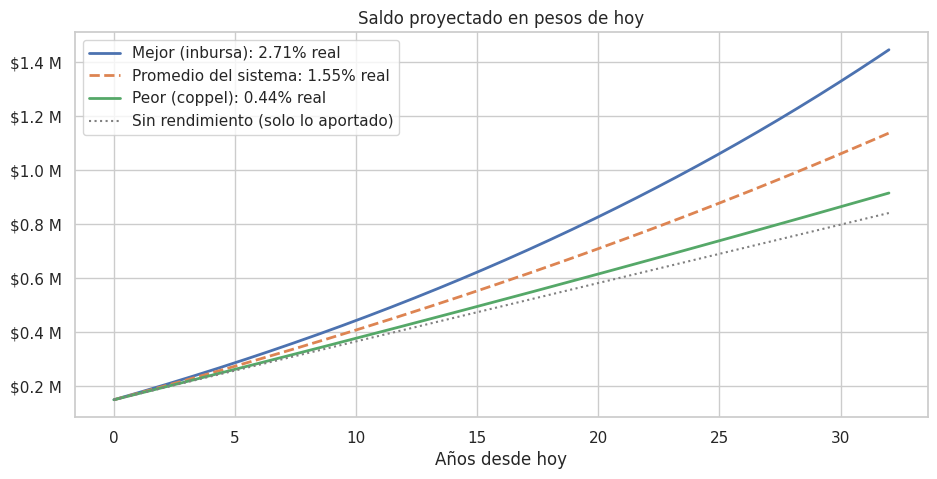

mejor:    $1,445,328
promedio: $1,137,020
peor:     $915,168
diferencia mejor menos peor: $530,160  (57.9% más)


In [5]:
mejor, peor = rend.idxmax(), rend.idxmin()
anios_eje = np.arange(0, ANIOS * 12 + 1) / 12

fig, ax = plt.subplots(figsize=(11, 5))
for nombre, r, estilo in [(f"Mejor ({mejor})", rend.max(), "-"), ("Promedio del sistema", prom_sistema, "--"), (f"Peor ({peor})", rend.min(), "-")]:
    ax.plot(anios_eje, proyectar(SALDO_INICIAL, APORTE_MENSUAL, ANIOS, r, CRECIMIENTO_APORTE_REAL), estilo, lw=2, label=f"{nombre}: {r:.2f}% real")
ax.plot(anios_eje, proyectar(SALDO_INICIAL, APORTE_MENSUAL, ANIOS, 0.0, CRECIMIENTO_APORTE_REAL), ":", color="gray", label="Sin rendimiento (solo lo aportado)")
ax.yaxis.set_major_formatter(fmt_pesos)
ax.set_xlabel("Años desde hoy")
ax.set_title("Saldo proyectado en pesos de hoy")
ax.legend()
guardar("02_trayectorias")
plt.show()

s_mejor = saldo_final(SALDO_INICIAL, APORTE_MENSUAL, ANIOS, rend.max(), CRECIMIENTO_APORTE_REAL)
s_peor = saldo_final(SALDO_INICIAL, APORTE_MENSUAL, ANIOS, rend.min(), CRECIMIENTO_APORTE_REAL)
s_prom = saldo_final(SALDO_INICIAL, APORTE_MENSUAL, ANIOS, prom_sistema, CRECIMIENTO_APORTE_REAL)
print(f"mejor:    ${s_mejor:,.0f}\npromedio: ${s_prom:,.0f}\npeor:     ${s_peor:,.0f}")
print(f"diferencia mejor menos peor: ${s_mejor - s_peor:,.0f}  ({(s_mejor / s_peor - 1) * 100:.1f}% más)")

## 6. ¿Se mantendrá la ventaja?
En el notebook 00 vi que el ranking de corto plazo explica poco del largo plazo, así que no es seguro que la AFORE que ganó los últimos 5 años siga ganando durante 32. Pruebo qué pasa si solo se mantiene una parte de la diferencia frente al promedio. Con persistencia 1 la diferencia observada se repite igual, y con 0 todas rinden lo mismo.

In [6]:
filas = []
for p in [0.0, 0.25, 0.5, 0.75, 1.0]:
    r_aj = ajustar_persistencia(rend, p)
    s = {a: saldo_final(SALDO_INICIAL, APORTE_MENSUAL, ANIOS, r_aj[a], CRECIMIENTO_APORTE_REAL) for a in rend.index}
    filas.append({"persistencia": p, "saldo_mejor": max(s.values()), "saldo_peor": min(s.values()),
                  "diferencia_$": max(s.values()) - min(s.values())})
pers = pd.DataFrame(filas).set_index("persistencia")
pers["diferencia_%"] = (pers["saldo_mejor"] / pers["saldo_peor"] - 1) * 100
display(pers.round(1))

,saldo_mejor,saldo_peor,diferencia_$,diferencia_%
persistencia,,,,
0.00,1165568.5,1165568.5,0.0,0.0
0.25,1229017.0,1095908.1,133108.8,12.1
0.50,1296600.8,1031196.8,265404.0,25.7
0.75,1368603.5,971064.2,397539.3,40.9
1.00,1445328.2,915168.1,530160.1,57.9


## 7. ¿Pesa más la AFORE o el supuesto de rendimiento?
Compara la diferencia entre elegir la mejor y la peor AFORE contra el efecto de equivocarse en el rendimiento real futuro, igual para todas.

,saldo_final,vs_rend_anterior_$
rend_real_%,,
0,841200.0,NaN
1,1019818.0,178618.0
2,1246711.0,226892.0
3,1535832.0,289122.0
4,1905214.0,369382.0
5,2378141.0,472926.0


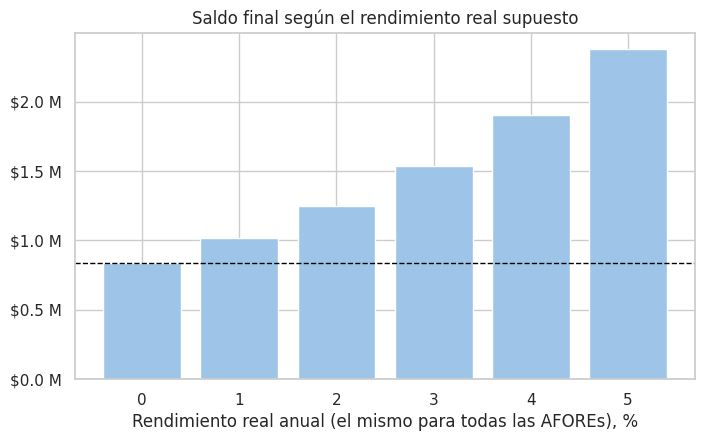

In [7]:
sup = pd.DataFrame({r: [saldo_final(SALDO_INICIAL, APORTE_MENSUAL, ANIOS, r, CRECIMIENTO_APORTE_REAL)] for r in [0, 1, 2, 3, 4, 5]},
                   index=["saldo_final"]).T
sup.index.name = "rend_real_%"
sup["vs_rend_anterior_$"] = sup["saldo_final"].diff()
display(sup.round(0))

plt.figure(figsize=(8, 4.5))
plt.bar(sup.index.astype(str), sup["saldo_final"], color="#9ec5e8")
plt.axhline(aportado, color="black", ls="--", lw=1)
plt.gca().yaxis.set_major_formatter(fmt_pesos)
plt.xlabel("Rendimiento real anual (el mismo para todas las AFOREs), %")
plt.title("Saldo final según el rendimiento real supuesto")
guardar("03_sensibilidad_supuesto")
plt.show()

## Qué encontré (perfil de ejemplo: SB 90-94, 32 años, $150,000 de saldo y $1,800 al mes)

En total se aportarían $841,200. Con el rendimiento real de cada AFORE, el saldo al retiro en pesos de hoy va de $915,168 (Coppel) a $1,445,328 (Inbursa), con el promedio del sistema en unos $1,137,020. La diferencia entre la mejor y la peor es de $530,160 (58% más), pero eso es si el rendimiento de los últimos 5 años se mantiene por 32 años, que es el caso más optimista para elegir bien.

Es difícil que la ventaja se mantenga completa. Si solo se mantuviera la mitad de la diferencia frente al promedio, la brecha entre mejor y peor baja a unos $265,000 (26%), y con un cuarto baja a unos $133,000 (12%).

El supuesto de rendimiento pesa tanto como la AFORE. Con las mismas condiciones para todas, pasar de 2% a 3% de rendimiento real anual cambia el saldo final en unos $289,000, comparable a la diferencia entre la mejor y la peor AFORE si se mantuviera la mitad de su ventaja.

Mi lectura es que elegir una AFORE con buen rendimiento histórico ayuda pero no garantiza nada. Lo que más mueve el resultado es cuánto se ahorra, durante cuánto tiempo y qué rendimiento real se logra en el largo plazo.

## Limitaciones
- Uso el rendimiento de los últimos 5 años (2021 a 2025), que incluye la caída de 2022 y un rebote fuerte, y no representa necesariamente los próximos 30.
- El ahorro mensual lo pone la persona, no se calcula desde el sueldo.
- No considero retiros por desempleo, cambios de AFORE, semanas cotizadas ni la pensión que resulte de ese saldo.
- Los rendimientos reales usan el INPC de `data/inpc_mensual.csv` (hay que verificarlo contra INEGI) y el archivo de CONSAR, que según una fuente secundaria ya viene neto de comisión.